In [ ]:
import geopandas as gpd
import pandas as pd
from datetime import datetime


In [ ]:
def filter_sinkholes_by_year(shapefile_path, year, output_path):
    # Load the shapefile
    gdf = gpd.read_file(shapefile_path)
    
    # Create the start and end year columns
    gdf['Start_Year'] = gdf['Start_Date']
    gdf['End_Year'] = gdf['End_Date']
    
    # Filter based on the given year
    filtered_gdf = gdf[
        (gdf['Start_Year'] <= year) &
        ((gdf['End_Year'] > year) | (gdf['End_Date'].isnull()))
    ]
    
    # Save the filtered GeoDataFrame as a new shapefile
    filtered_gdf.to_file(output_path, driver='ESRI Shapefile')

    return filtered_gdf

# Example usage
shapefile_path = '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2023_main.shp'
output_path = '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2016_filtered.shp'
year = 2016

filtered_gdf = filter_sinkholes_by_year(shapefile_path, year, output_path)


/var/folders/6p/ptt93q_526s0h7wwz3q0s99m0000gn/T/ipykernel_72853/2066495775.py:1: UserWarning: Shapely 2.0 is installed, but because PyGEOS is also installed, GeoPandas will still use PyGEOS by default for now. To force to use and test Shapely 2.0, you have to set the environment variable USE_PYGEOS=0. You can do this before starting the Python process, or in your code before importing geopandas:

import os
os.environ['USE_PYGEOS'] = '0'
import geopandas

In a future release, GeoPandas will switch to using Shapely by default. If you are using PyGEOS directly (calling PyGEOS functions on geometries from GeoPandas), this will then stop working and you are encouraged to migrate from PyGEOS to Shapely 2.0 (https://shapely.readthedocs.io/en/latest/migration_pygeos.html).
  import geopandas as gpd


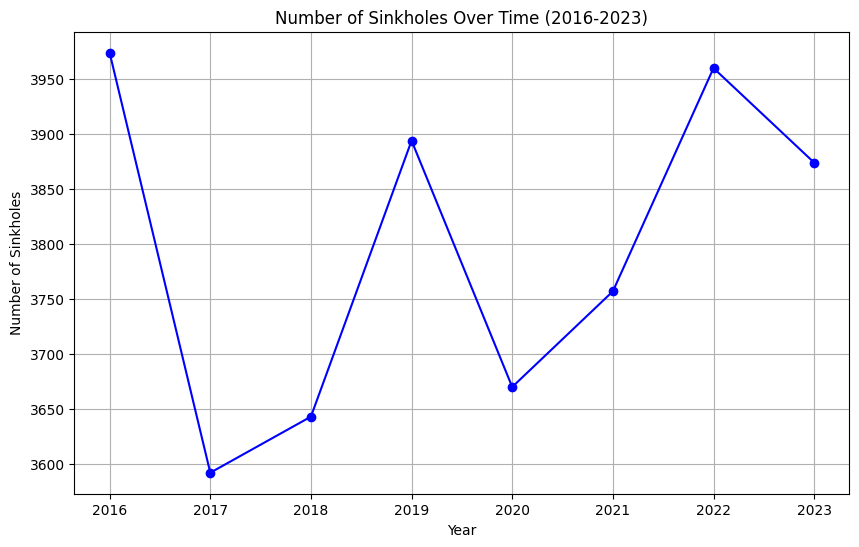

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt

def count_sinkholes_per_year(shapefile_paths):
    sinkhole_counts = {}
    
    for year, path in shapefile_paths.items():
        # Load the shapefile
        gdf = gpd.read_file(path)
        # Count the number of polygons (sinkholes)
        sinkhole_counts[year] = len(gdf)
    
    return sinkhole_counts

def plot_sinkhole_counts(sinkhole_counts):
    # Sort the dictionary by year
    sorted_years = sorted(sinkhole_counts.keys())
    counts = [sinkhole_counts[year] for year in sorted_years]
    
    # Plotting
    plt.figure(figsize=(10, 6))
    plt.plot(sorted_years, counts, marker='o', linestyle='-', color='blue')
    plt.xlabel('Year')
    plt.ylabel('Number of Sinkholes')
    plt.title('Number of Sinkholes Over Time (2016-2023)')
    plt.grid(True)
    plt.show()

# Example usage
shapefile_paths = {
    2016: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2016_filtered.shp',
    2017: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2017_filtered.shp',
    2018: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2018_filtered.shp',
    2019: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2019_filtered.shp',
    2020: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2020_filtered.shp',
    2021: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2021_filtered.shp',
    2022: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2022_filtered.shp',
    2023: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2023_filtered.shp',
}

sinkhole_counts = count_sinkholes_per_year(shapefile_paths)
plot_sinkhole_counts(sinkhole_counts)


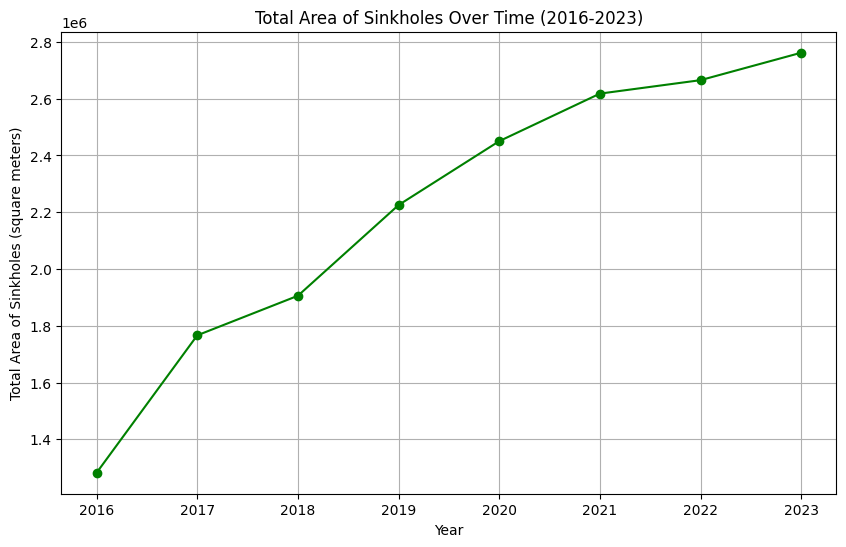

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt

def calculate_total_area_per_year(shapefile_paths):
    total_areas = {}
    
    for year, path in shapefile_paths.items():
        # Load the shapefile
        gdf = gpd.read_file(path)
        # Ensure the GeoDataFrame has a consistent CRS (Coordinate Reference System)
        gdf = gdf.to_crs(epsg=3395)  # Use an appropriate projected CRS for area calculation
        
        # Calculate the total area of all polygons (sinkholes) in square meters
        total_area = gdf.geometry.area.sum()
        
        # Store the total area in the dictionary
        total_areas[year] = total_area
    
    return total_areas

def plot_total_area(total_areas):
    # Sort the dictionary by year
    sorted_years = sorted(total_areas.keys())
    areas = [total_areas[year] for year in sorted_years]
    
    # Plotting
    plt.figure(figsize=(10, 6))
    plt.plot(sorted_years, areas, marker='o', linestyle='-', color='green')
    plt.xlabel('Year')
    plt.ylabel('Total Area of Sinkholes (square meters)')
    plt.title('Total Area of Sinkholes Over Time (2016-2023)')
    plt.grid(True)
    plt.show()
    
    
shapefile_paths = {
    2016: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2016_filtered.shp',
    2017: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2017_filtered.shp',
    2018: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2018_filtered.shp',
    2019: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2019_filtered.shp',
    2020: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2020_filtered.shp',
    2021: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2021_filtered.shp',
    2022: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2022_filtered.shp',
    2023: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2023_filtered.shp',
}

total_areas = calculate_total_area_per_year(shapefile_paths)
plot_total_area(total_areas)

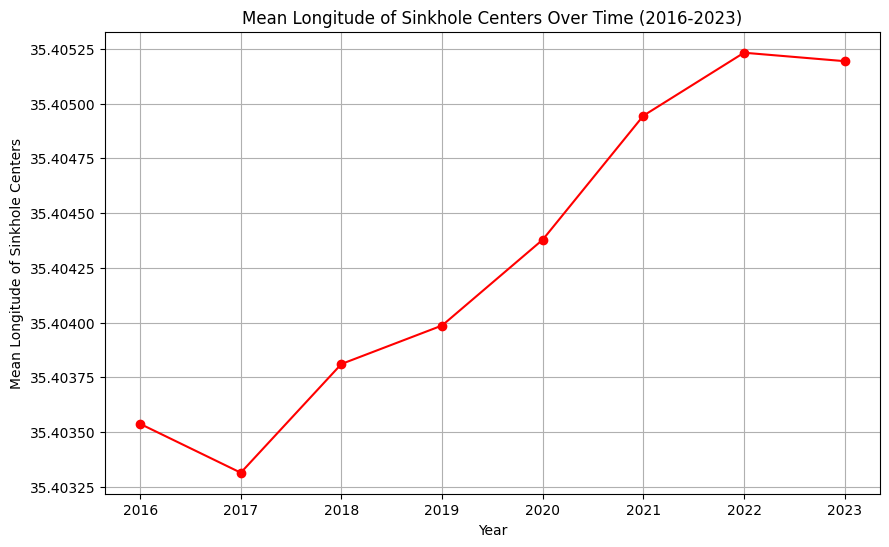

In [5]:
import geopandas as gpd
import matplotlib.pyplot as plt

def calculate_mean_longitude_per_year(shapefile_paths):
    mean_longitudes = {}
    
    for year, path in shapefile_paths.items():
        # Load the shapefile
        gdf = gpd.read_file(path)
        
        # Reproject to a suitable projected CRS for accurate area calculations
        # You can use EPSG:3395 (WGS 84 / World Mercator) or any other appropriate CRS
        gdf = gdf.to_crs(epsg=3395)
        
        # Calculate the centroids of the polygons (sinkholes)
        gdf['centroid'] = gdf.geometry.centroid
        
        # Reproject centroids back to geographic CRS for correct longitude extraction
        centroids_geog = gdf['centroid'].to_crs(epsg=4326)
        
        # Extract the longitude (x-coordinate) of the centroids
        longitudes = centroids_geog.x
        
        # Calculate the mean longitude
        mean_longitude = longitudes.mean()
        
        # Store the mean longitude in the dictionary
        mean_longitudes[year] = mean_longitude
    
    return mean_longitudes

import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

def plot_mean_longitude(mean_longitudes):
    # Sort the dictionary by year
    sorted_years = sorted(mean_longitudes.keys())
    longitudes = [mean_longitudes[year] for year in sorted_years]
    
    # Plotting
    plt.figure(figsize=(10, 6))
    plt.plot(sorted_years, longitudes, marker='o', linestyle='-', color='red')
    plt.xlabel('Year')
    plt.ylabel('Mean Longitude of Sinkhole Centers')
    plt.title('Mean Longitude of Sinkhole Centers Over Time (2016-2023)')
    
    # Set the y-axis to use plain (non-scientific) formatting
    plt.gca().yaxis.set_major_formatter(ScalarFormatter(useOffset=False))
    
    plt.grid(True)
    plt.show()

# Example usage
shapefile_paths = {
    2016: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2016_filtered.shp',
    2017: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2017_filtered.shp',
    2018: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2018_filtered.shp',
    2019: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2019_filtered.shp',
    2020: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2020_filtered.shp',
    2021: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2021_filtered.shp',
    2022: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2022_filtered.shp',
    2023: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2023_filtered.shp',
}

mean_longitudes = calculate_mean_longitude_per_year(shapefile_paths)
plot_mean_longitude(mean_longitudes)


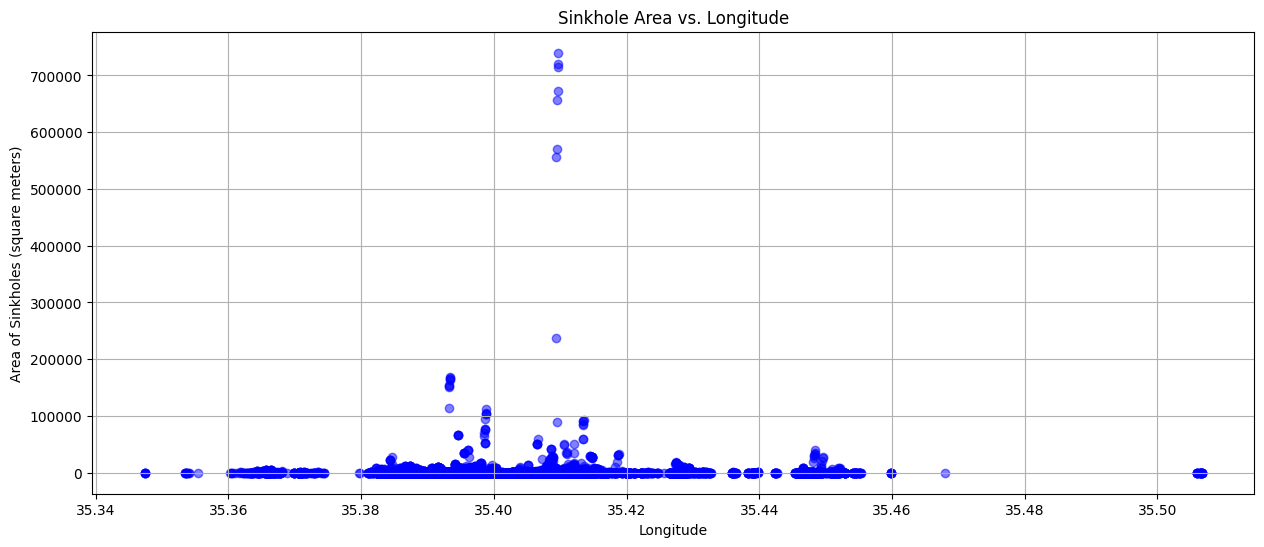

In [12]:
import geopandas as gpd
import matplotlib.pyplot as plt

def calculate_area_and_longitude(shapefile_paths):
    areas = []
    longitudes = []
    
    for year, path in shapefile_paths.items():
        # Load the shapefile
        gdf = gpd.read_file(path)
        
        # Reproject to a suitable projected CRS for accurate area calculations
        gdf = gdf.to_crs(epsg=3395)
        
        # Calculate the area of each polygon (sinkhole)
        gdf['area'] = gdf.geometry.area
        
        # Calculate the centroids of the polygons (sinkholes)
        gdf['centroid'] = gdf.geometry.centroid
        
        # Reproject centroids back to geographic CRS for correct longitude extraction
        centroids_geog = gdf['centroid'].to_crs(epsg=4326)
        
        # Extract the longitude (x-coordinate) of the centroids
        gdf['longitude'] = centroids_geog.x
        
        # Append the area and longitude values to lists
        areas.extend(gdf['area'].tolist())
        longitudes.extend(gdf['longitude'].tolist())
    
    return areas, longitudes

def plot_area_vs_longitude(areas, longitudes):
    # Plotting
    plt.figure(figsize=(15, 6))
    plt.scatter(longitudes, areas, color='blue', alpha=0.5)
    plt.xlabel('Longitude')
    plt.ylabel('Area of Sinkholes (square meters)')
    plt.title('Sinkhole Area vs. Longitude')
    
    # Set the y-axis to use plain (non-scientific) formatting
    plt.gca().yaxis.set_major_formatter(ScalarFormatter(useOffset=False))
    # limit y axis to 0-1000
    # plt.ylim(0, 1000)
    plt.grid(True)
    plt.show()

# Example usage
shapefile_paths = {
    2016: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2016_filtered.shp',
    2017: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2017_filtered.shp',
    2018: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2018_filtered.shp',
    2019: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2019_filtered.shp',
    2020: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2020_filtered.shp',
    2021: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2021_filtered.shp',
    2022: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2022_filtered.shp',
    2023: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2023_filtered.shp',
}

areas, longitudes = calculate_area_and_longitude(shapefile_paths)
plot_area_vs_longitude(areas, longitudes)


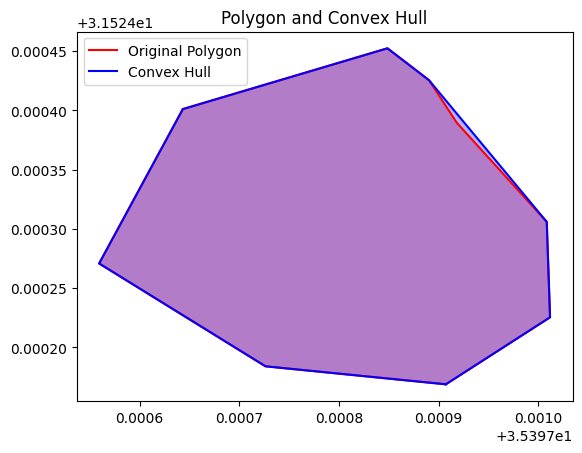

348.35807447562536


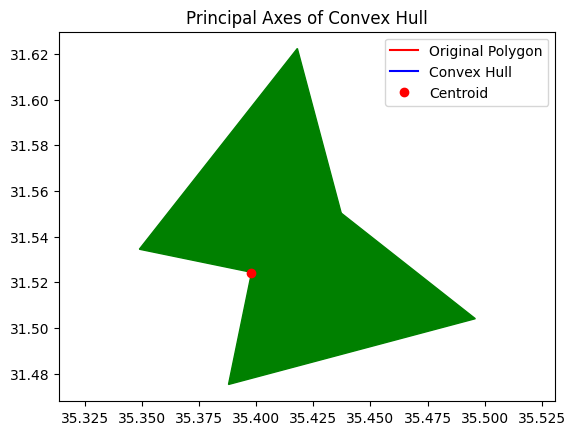

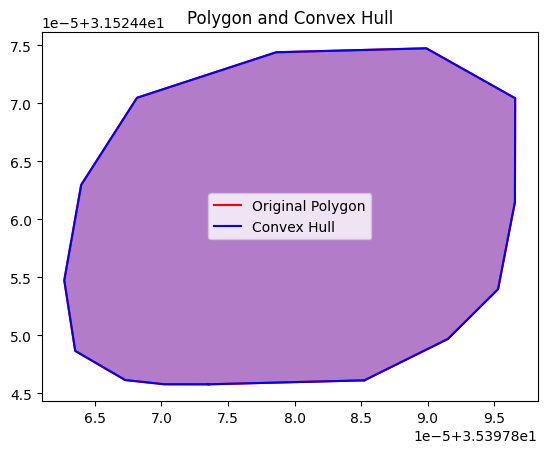

32.942736988912415


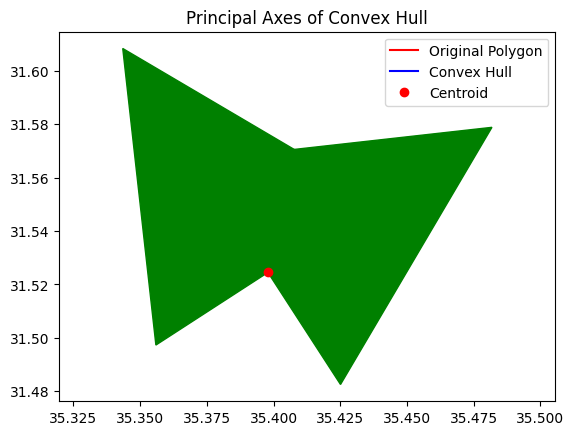

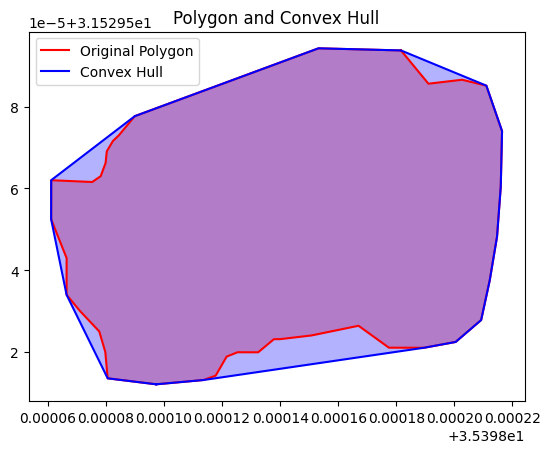

7.81478744783614


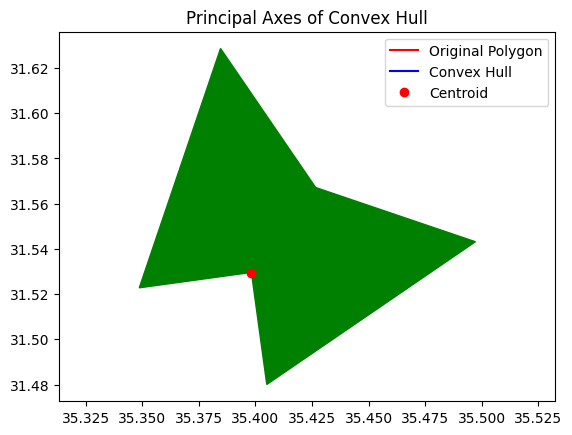

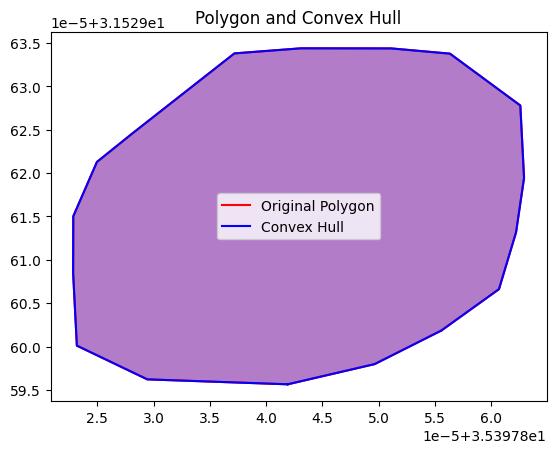

40.32758430515742


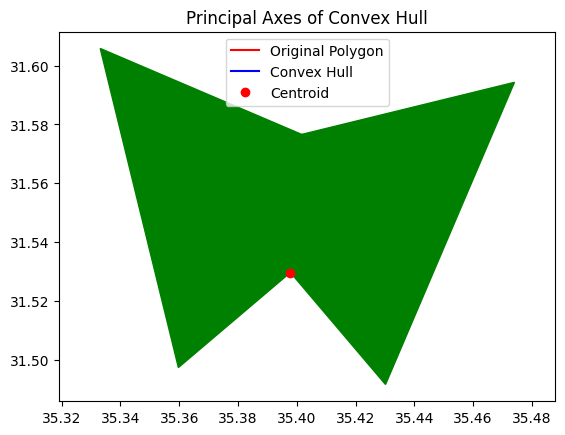

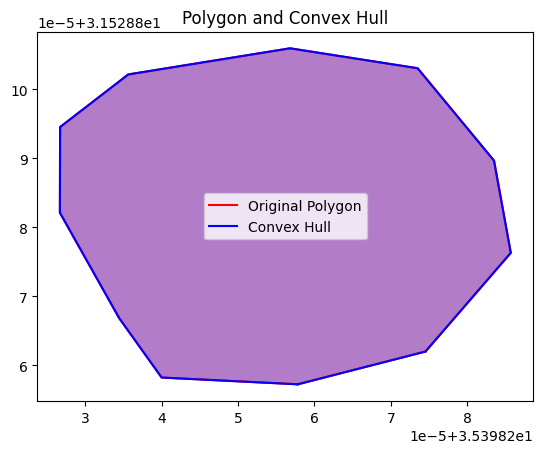

352.39073730405266


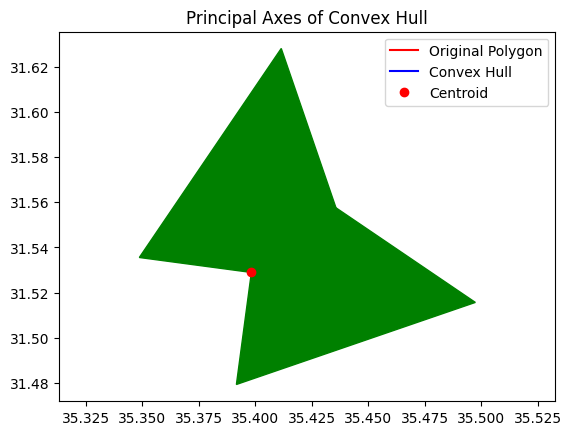

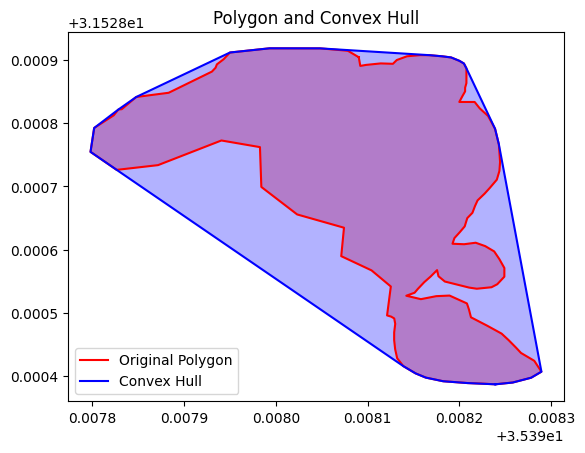

294.92485177652327


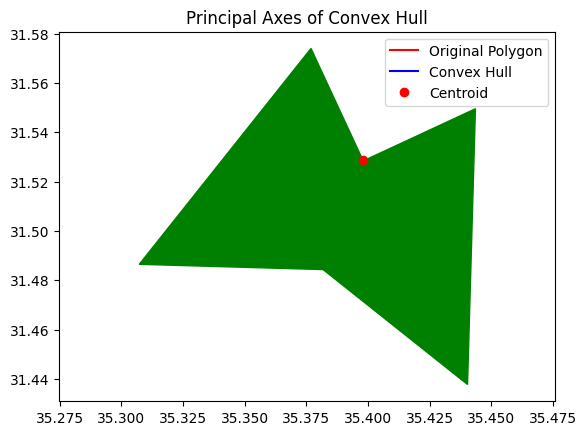

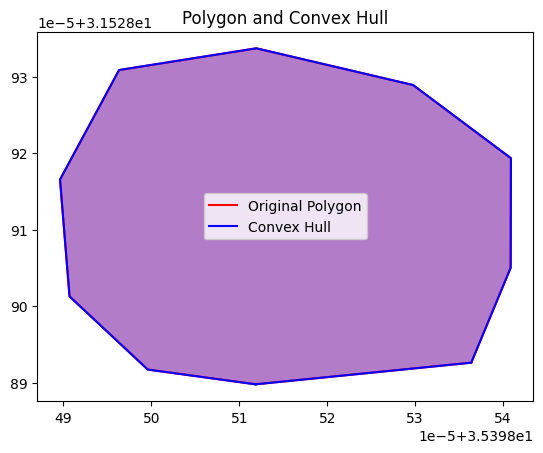

0.564092645173386


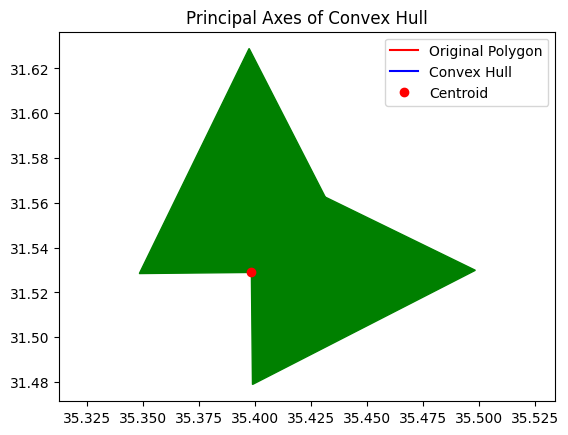

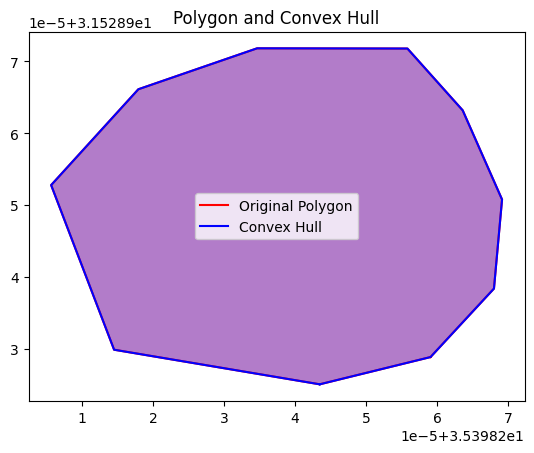

352.7408082913963


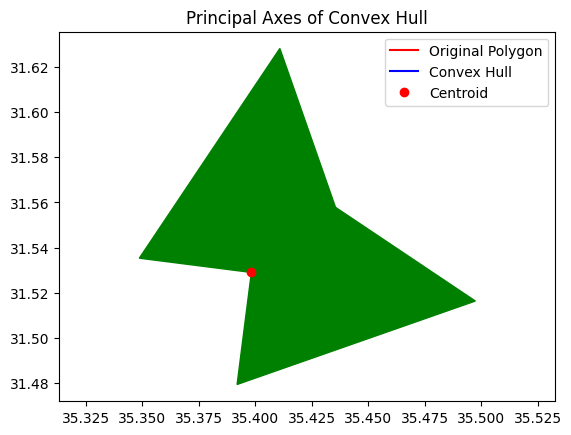

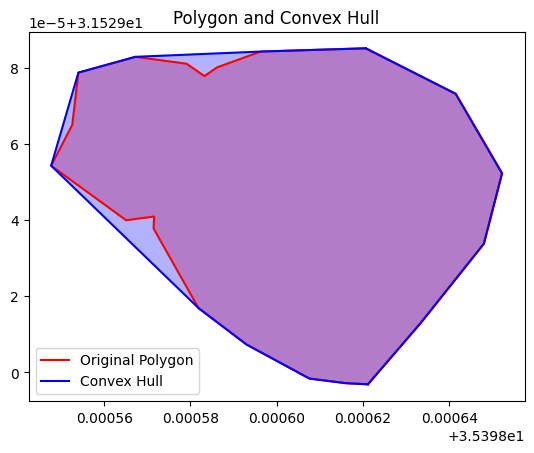

304.66346836796777


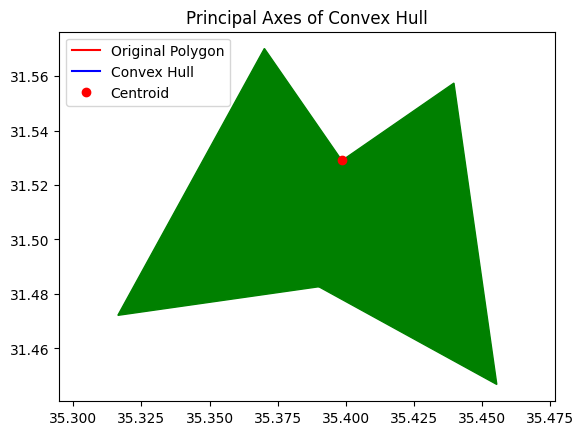

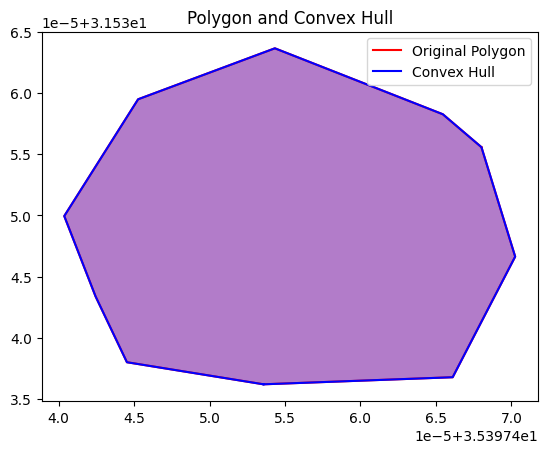

27.574829757714436


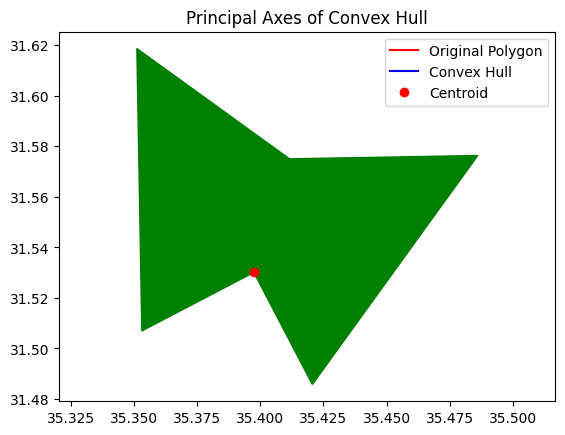

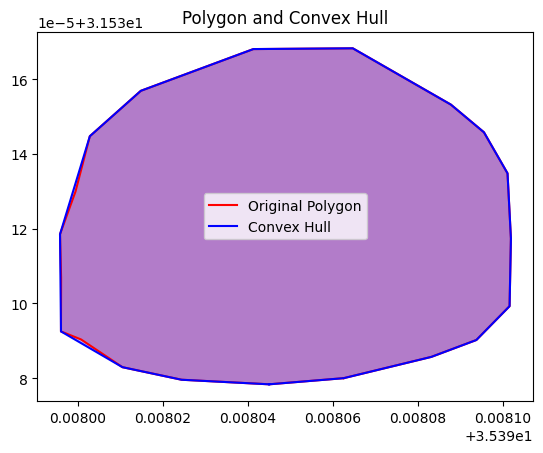

13.137060901180572


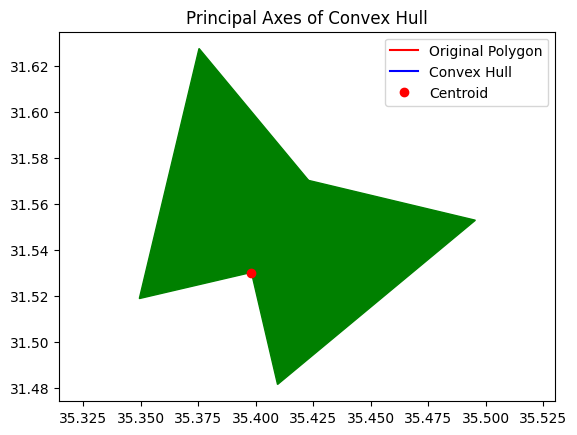

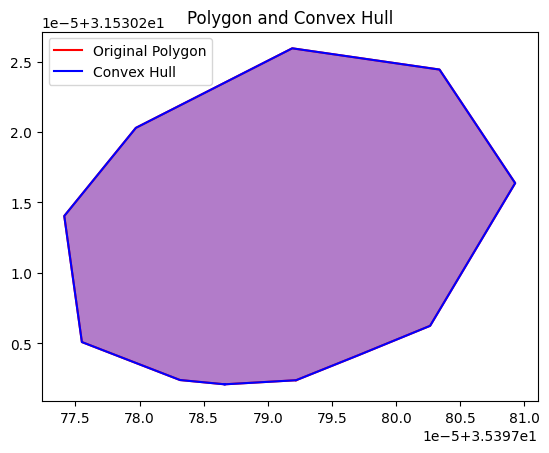

23.114379054741548


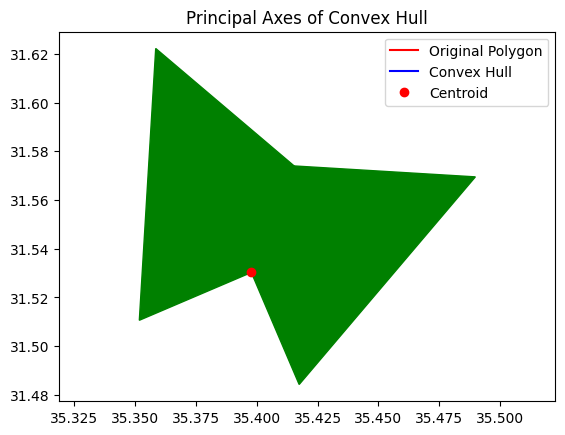

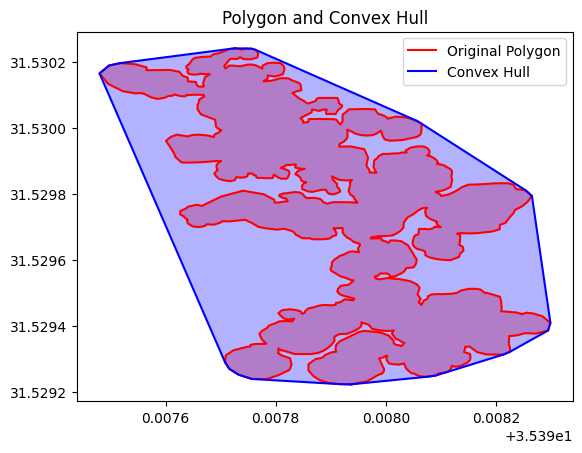

288.8401922977324


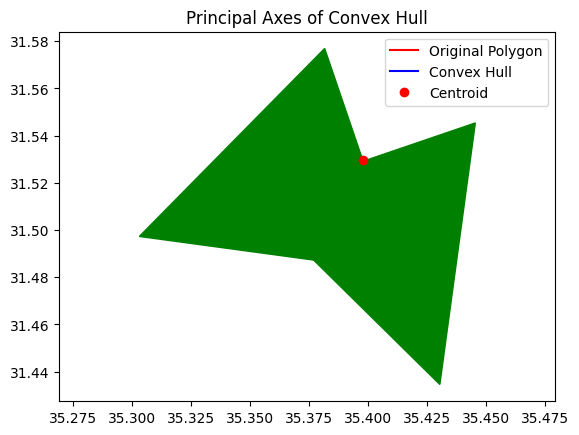

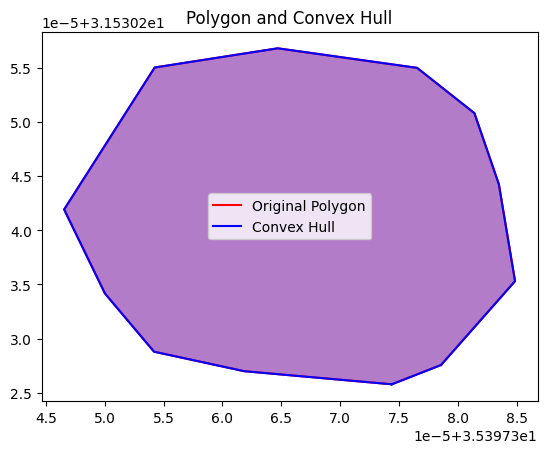

357.7417756253012


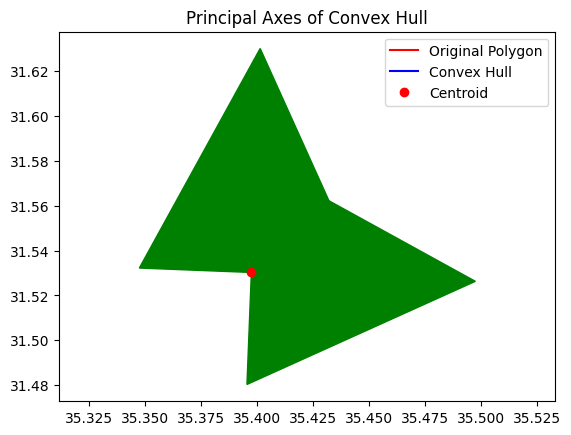

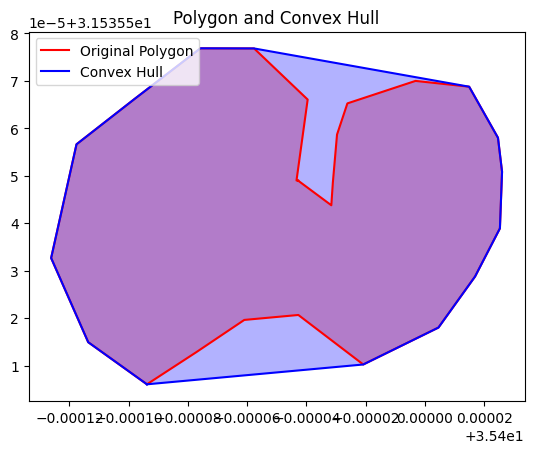

3.6126709050633017


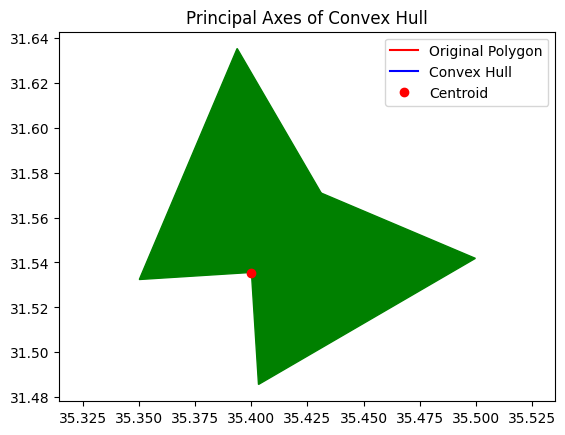

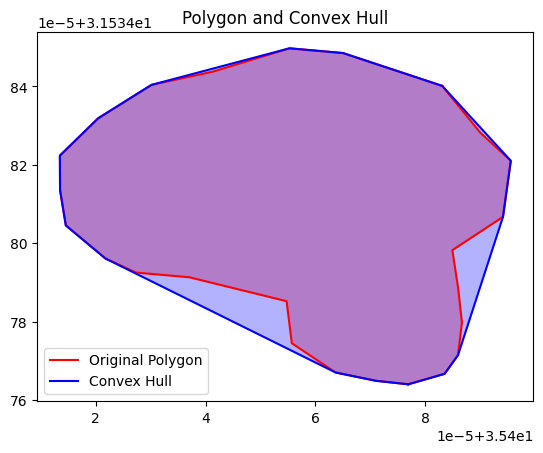

310.4017119722753


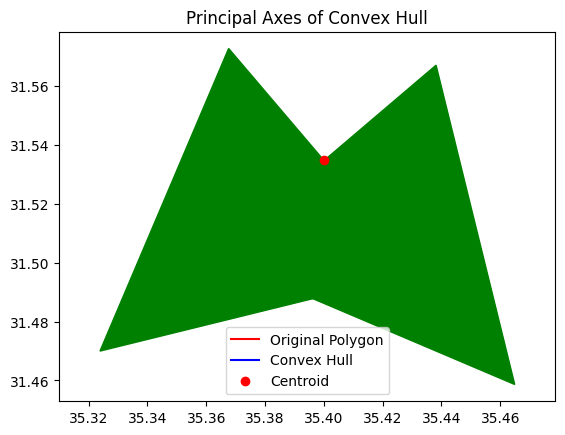

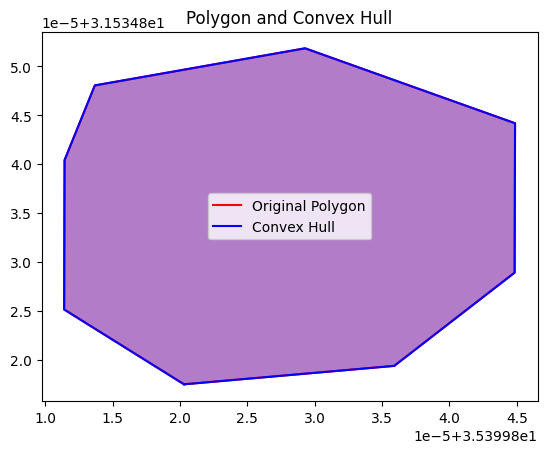

235.07979984897855


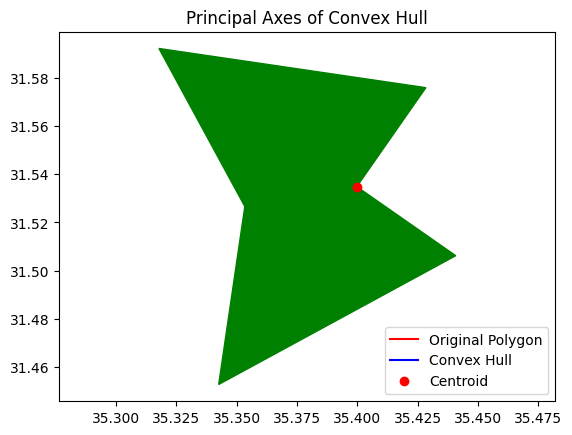

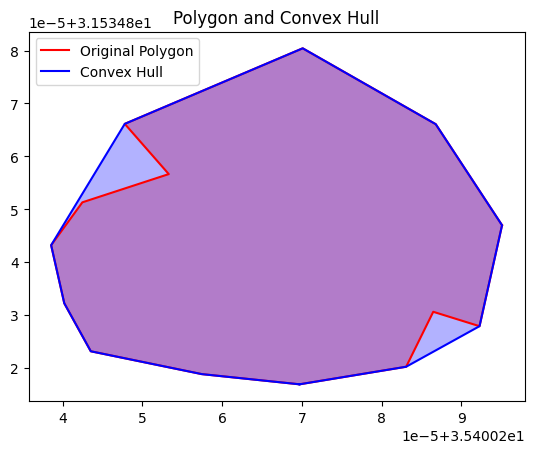

251.9549677756019


KeyboardInterrupt: 

In [33]:
import geopandas as gpd
import numpy as np
from shapely.geometry import Polygon
from shapely.affinity import rotate
from skimage.draw import disk
from shapely.geometry import LineString
from shapely.affinity import affine_transform
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from matplotlib.patches import FancyArrowPatch

def calculate_longest_diameter_direction(polygon):
    # Compute the convex hull
    hull = polygon.convex_hull


    
    # Fit an ellipse to the convex hull
    if hull.area == 0:
        return None  # Avoid computation for empty or degenerate geometries
    
    x, y = hull.exterior.xy
    centroid = hull.centroid
    
    # Create a polygon buffer for the convex hull
    coords = np.array([x, y]).T
    centroid = np.mean(coords, axis=0)
    
    # Compute the principal axes using the covariance matrix
    cov_matrix = np.cov(coords.T)
    eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)
    
    # The direction of the largest eigenvalue corresponds to the longest axis
    angle = np.arctan2(eigenvectors[1, eigenvalues.argmax()], eigenvectors[0, eigenvalues.argmax()])
    
    # Plot the original polygon
    x, y = polygon.exterior.xy
    plt.figure()
    plt.plot(x, y, color='red', label='Original Polygon')
    plt.fill(x, y, alpha=0.3, fc='red', ec='none')

    # Plot the convex hull
    hull_x, hull_y = hull.exterior.xy
    plt.plot(hull_x, hull_y, color='blue', label='Convex Hull')
    plt.fill(hull_x, hull_y, alpha=0.3, fc='blue', ec='none')

    plt.title('Polygon and Convex Hull')
    plt.legend()
    plt.show()
    
    print(np.degrees(angle) % 360)
    
    
    # Convert radians to degrees
    return np.degrees(angle) % 360

# Example usage
shapefile_paths = {
    2016: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2016_filtered.shp',
    2017: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2017_filtered.shp',
    2018: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2018_filtered.shp',
    2019: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2019_filtered.shp',
    2020: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2020_filtered.shp',
    2021: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2021_filtered.shp',
    2022: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2022_filtered.shp',
    2023: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2023_filtered.shp',
}

directions = []

for year, path in shapefile_paths.items():
    gdf = gpd.read_file(path)
    for _, row in gdf.iterrows():
        direction = calculate_longest_diameter_direction(row.geometry)
        if direction is not None:
            directions.append(direction)



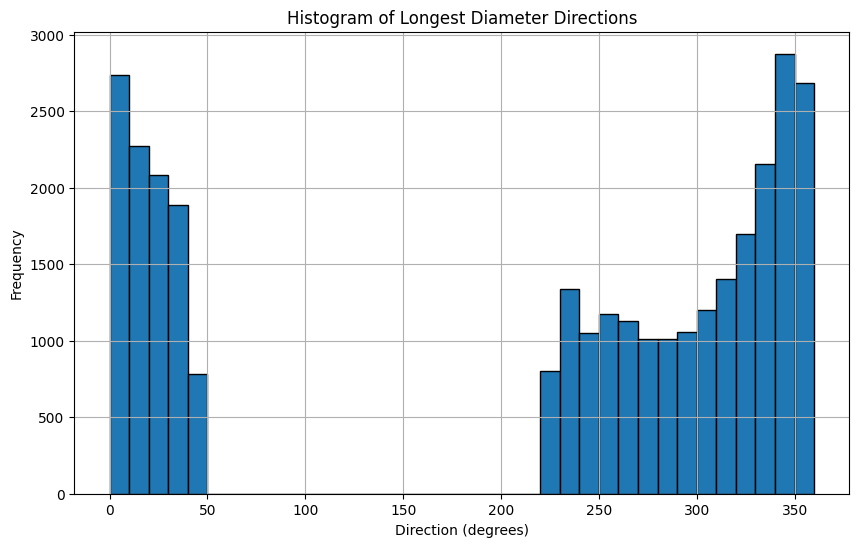

In [14]:
def plot_histogram(directions):
    plt.figure(figsize=(10, 6))
    plt.hist(directions, bins=36, edgecolor='black')
    plt.xlabel('Direction (degrees)')
    plt.ylabel('Frequency')
    plt.title('Histogram of Longest Diameter Directions')
    plt.grid(True)
    plt.show()

# Plotting
plot_histogram(directions)


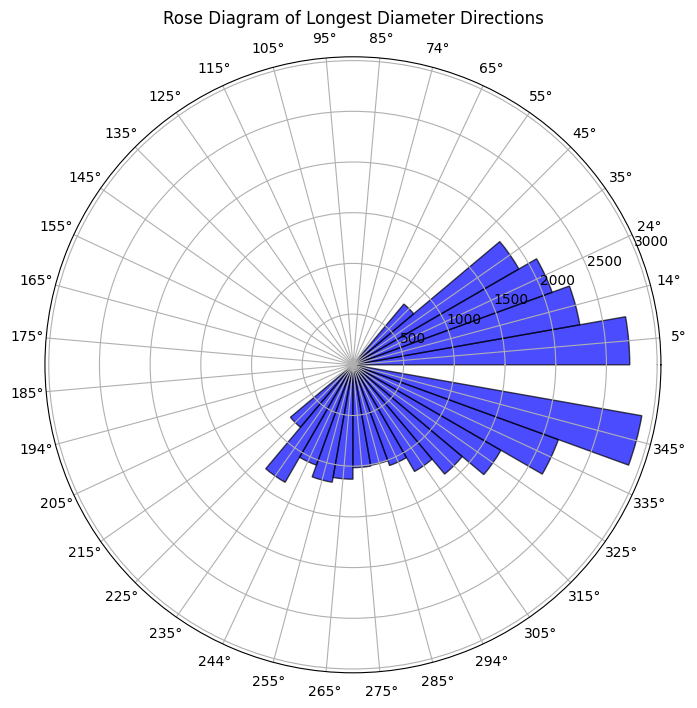

In [15]:
import matplotlib.pyplot as plt

def plot_rose_diagram(directions):
    # Convert directions to radians
    directions_rad = np.radians(directions)
    
    # Create bins
    bins = np.linspace(0, 2 * np.pi, 36, endpoint=False)
    hist, _ = np.histogram(directions_rad, bins=bins)
    
    # Create a figure and polar plot
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(111, polar=True)
    
    # Plot the histogram in polar coordinates
    angles = (bins[:-1] + bins[1:]) / 2
    ax.bar(angles, hist, width=(2 * np.pi / len(bins)), color='blue', edgecolor='black', alpha=0.7)
    
    ax.set_xticks(angles)
    ax.set_xticklabels([f'{int(np.degrees(a))}°' for a in angles])
    ax.set_title('Rose Diagram of Longest Diameter Directions')
    plt.show()

# Plotting
plot_rose_diagram(directions)


In [20]:
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import Polygon
from shapely.affinity import affine_transform

def calculate_diameters_and_directions(shapefile_paths):
    directions = []
    ratios = []
    
    for year, path in shapefile_paths.items():
        # Load the shapefile
        gdf = gpd.read_file(path)
        
        for _, row in gdf.iterrows():
            geom = row.geometry
            
            # Get the minimum bounding rectangle (MBR) of the sinkhole
            mbr = geom.minimum_rotated_rectangle
            
            # Extract the coordinates of the MBR
            coords = np.array(mbr.exterior.coords)
            
            # Calculate lengths of the major and minor axes
            lengths = [np.linalg.norm(coords[i] - coords[(i + 1) % len(coords)]) for i in range(len(coords))]
            major_axis = max(lengths)
            minor_axis = min(lengths)
            
            # Calculate the angle of the major axis
            major_axis_vector = coords[np.argmax(lengths)] - coords[np.argmin(lengths)]
            angle = np.arctan2(major_axis_vector[1], major_axis_vector[0]) * (180 / np.pi)
            
            # Normalize angle to [0, 360) range
            angle = angle % 360
            
            directions.append(angle)
            ratios.append(minor_axis / major_axis)
    
    return directions, ratios



In [21]:
def plot_histogram(directions, ratios):
    plt.figure(figsize=(12, 6))
    
    # Plot histogram of directions
    plt.subplot(1, 2, 1)
    plt.hist(directions, bins=36, edgecolor='black', alpha=0.7)
    plt.xlabel('Direction (degrees)')
    plt.ylabel('Frequency')
    plt.title('Histogram of Longest Diameter Directions')
    
    # Plot histogram of ratios
    plt.subplot(1, 2, 2)
    plt.hist(ratios, bins=10, edgecolor='black', alpha=0.7, color='orange')
    plt.xlabel('Ratio of Minor to Major Axis')
    plt.ylabel('Frequency')
    plt.title('Histogram of Axis Ratios')
    
    plt.tight_layout()
    plt.show()


In [22]:
def plot_rose_diagram(directions, ratios):
    plt.figure(figsize=(8, 8))
    ax = plt.subplot(111, polar=True)
    
    # Convert directions to radians
    directions_rad = np.deg2rad(directions)
    
    # Create histogram data for the rose diagram
    histogram, bins = np.histogram(directions_rad, bins=36, range=(0, 2 * np.pi))
    bins = 0.5 * (bins[:-1] + bins[1:])
    
    # Plot the rose diagram
    ax.bar(bins, histogram, width=np.deg2rad(10), color='blue', edgecolor='black', alpha=0.7)
    
    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)
    ax.set_rlabel_position(-22.5)
    ax.set_xlabel('Direction (degrees)')
    plt.title('Rose Diagram of Longest Diameter Directions')
    plt.show()


In [25]:
def plot_area_vs_longitude_with_ratio(areas, longitudes, ratios):
    plt.figure(figsize=(10, 6))
    
    # Color by ratio
    color = ['red' if ratio > 0.4 else 'blue' for ratio in ratios]
    
    plt.scatter(longitudes, areas, c=color, alpha=0.4)
    plt.xlabel('Longitude')
    plt.ylabel('Area of Sinkholes (square meters)')
    plt.title('Sinkhole Area vs. Longitude')
    plt.grid(True)
    plt.show()


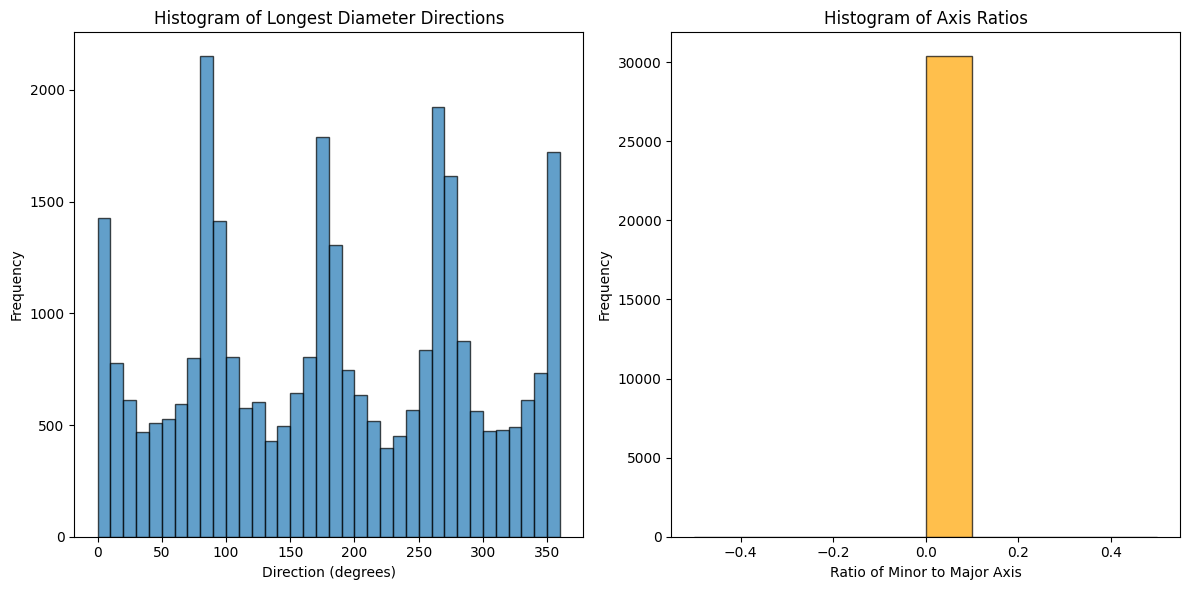

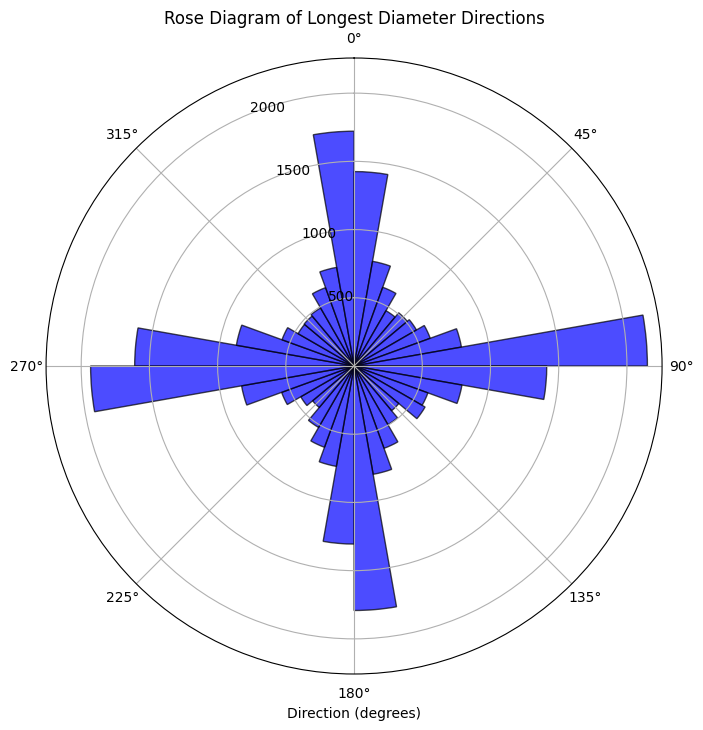

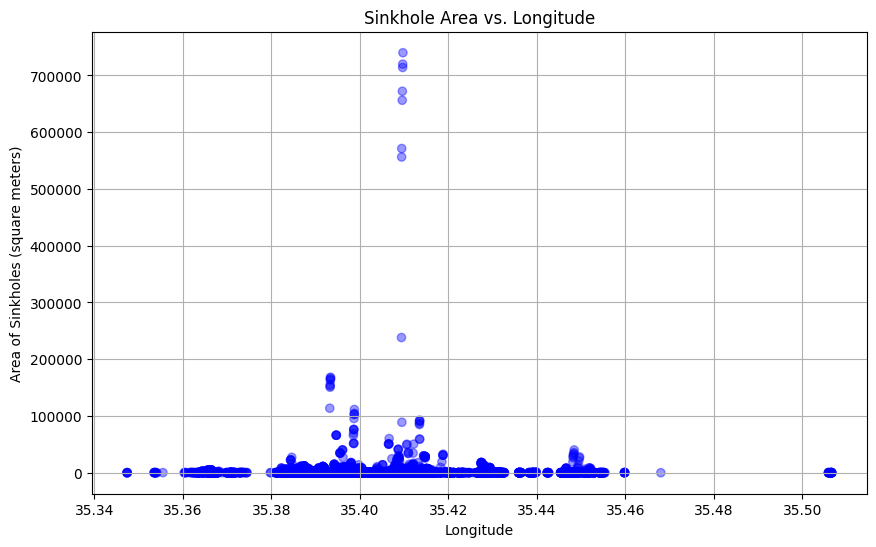

In [26]:
shapefile_paths = {
    2016: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2016_filtered.shp',
    2017: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2017_filtered.shp',
    2018: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2018_filtered.shp',
    2019: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2019_filtered.shp',
    2020: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2020_filtered.shp',
    2021: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2021_filtered.shp',
    2022: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2022_filtered.shp',
    2023: '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2023_filtered.shp',
}

directions, ratios = calculate_diameters_and_directions(shapefile_paths)
plot_histogram(directions, ratios)
plot_rose_diagram(directions, ratios)

# Additional example usage for color coding
areas, longitudes = calculate_area_and_longitude(shapefile_paths)
plot_area_vs_longitude_with_ratio(areas, longitudes, ratios)
